# GBE slider measurement inquiry

Does the slider starting position affect recorded happiness, and what does that mean for the mood × subsequent RPE question?

Notebook 2 picked up lots of ratings matching their starting value. Here I look more closely at the timing, the starting positions and where matching occurs, then try a couple of synthetic examples.

**Data scope:** sections 1–3 use the full release. Section 4 is synthetic. Further real-data modelling will use the existing development split, loaded separately in section 5. The earlier whole-release checks are already seen; the hold-out is reserved from further model development and testing the substantive relationship.

Still feasibility work. Nothing has been removed and the mood × RPE hypothesis hasn't been tested.

## 1. Load the data

Same released file as notebooks 1 and 2. The notebook is in the repository's `notebooks/` folder; raw data are outside the repository. Run from that folder.

Starting-value and timing definitions come from `README_Rutledge_GBE_risk_data.pdf`, alongside the MAT file. The dictionary describes `happinessRT` as time taken to answer the happiness question, in seconds. It does not provide slider movement logs.

In [7]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat

PROJECT_DIR = Path.cwd().parents[1]
DATA_PATH = PROJECT_DIR / "data" / "raw" / "gbe" / "Rutledge_GBE_risk_data_TOD.mat"

print("Data file found:", DATA_PATH.is_file())

Data file found: True


In [8]:
mat = loadmat(DATA_PATH, simplify_cells=True)
participants = mat["subjData"]

print("People:", len(participants))

People: 47067


In [9]:
def get_plays(participant):
    # same container handling as notebook 2
    if participant["nPlays"] == 1:
        return [participant["data"]]
    return list(participant["data"])

### Fields needed here

Column indices:

| Index | Field | Use |
|---:|---|---|
| 0 | `nTrial` | Trial order; row 1 stores the pre-task rating |
| 9 | `happiness` | Recorded rating; NaN between scheduled ratings |
| 10 | `startValue` | Recorded slider starting position |
| 11 | `happinessRT` | Recorded rating response time in seconds |

Keeping participant `id`, the derived available-play index and recorded `designVersion` with observations. Preserving `timesPlayed` separately since notebook 2 found repeated and decreasing attempt counters.

## 2. Recording and starting-value checks (full release)

### Rating response times

First check completeness, finite values, zero or negative times, and the spread of positive times by version and rating timing. No speed threshold yet.

Baseline is stored in Python row 0. Other scheduled ratings follow trial outcomes.

In [ ]:
# Store rating times for each version and timing
rating_times = {}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for row in rating_rows:
            timing = "baseline" if row == 0 else "post-outcome"
            key = (version, timing)

            if key not in rating_times:
                rating_times[key] = []

            rating_times[key].append(play[row, 11])

In [5]:
rt_summary = []

for (version, timing), values in sorted(rating_times.items()):
    values = np.asarray(values)
    positive = values[np.isfinite(values) & (values > 0)]

    rt_summary.append({
        "version": version,
        "timing": timing,
        "rating_rows": len(values),
        "missing_RT": np.isnan(values).sum(),
        "infinite_RT": np.isinf(values).sum(),
        "zero_RT": (values == 0).sum(),
        "negative_RT": (values < 0).sum(),
        "positive_min": positive.min() if len(positive) else np.nan,
        "positive_median": np.median(positive) if len(positive) else np.nan,
        "positive_p99": np.quantile(positive, 0.99) if len(positive) else np.nan,
        "positive_max": positive.max() if len(positive) else np.nan,
    })

pd.DataFrame(rt_summary)

,version,timing,rating_rows,missing_RT,infinite_RT,zero_RT,negative_RT,positive_min,positive_median,positive_p99,positive_max
0,1,baseline,35214,0,0,0,0,0.703,3.9680,20.98387,135553.078
1,1,post-outcome,387354,0,0,0,0,0.333,2.3160,12.07300,121599.648
2,2,baseline,1178,0,0,0,0,0.814,2.8740,17.03946,41928.078
3,2,post-outcome,12958,0,0,0,1,0.383,2.2340,17.19180,418320.188
4,3,baseline,5456,0,0,0,0,0.710,4.7330,17.89010,1109.751
5,3,post-outcome,60016,0,0,0,0,0.416,2.6170,10.56685,53364.066
6,4,baseline,10684,0,0,0,0,0.729,4.2645,23.19080,34959.227
7,4,post-outcome,117524,0,0,0,0,0.351,2.4250,12.58631,21427.496
8,5,baseline,38526,0,0,0,0,0.732,4.6040,18.36800,20222.434
9,5,post-outcome,423786,0,0,0,1,0.409,2.5120,9.76700,164789.812


Each scheduled rating has a recorded RT, with no missing, infinite or zero values. Two ratings have negative RTs, will locate those next. Some positive times are extremely long, the largest almost five days. Could reflect interruptions or recording issues. 

Baseline medians are higher than post-outcome medians in every version.

In [6]:
# Locate the two negative values

negative_rt_records = []

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        has_rating = ~np.isnan(play[:, 9])
        negative_rows = np.flatnonzero(has_rating & (play[:, 11] < 0))

        for row in negative_rows:
            negative_rt_records.append({
                "id": participant["id"],
                "available_play": play_index + 1,
                "version": int(versions[play_index]),
                "stored_trial_row": play[row, 0],
                "happiness": play[row, 9],
                "startValue": play[row, 10],
                "happinessRT": play[row, 11],
            })

pd.DataFrame(negative_rt_records)

,id,available_play,version,stored_trial_row,happiness,startValue,happinessRT
0,14801,8,2,11.0,50.0,50.0,-3.379
1,39807,2,5,28.0,77.0,59.0,-6.240


Just flagging these for now. No RT cutoff or rating exclusions. Compare the groups using medians, quantiles and curves rather than means that could be dominated by the very long times.

### RTs for matching and nonmatching ratings

Are matching ratings faster? RT summaries use positive, finite times; the two negative times stay flagged separately.

In [11]:
rt_by_match = {}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for row in rating_rows:
            timing = "baseline" if row == 0 else "post-outcome"
            # Check if the happiness rating matches the start value, ingoring floating point precision issues
            matches_start = bool(np.isclose(
                play[row, 9], play[row, 10], rtol=0, atol=1e-10
            ))
            key = (version, timing, matches_start)

            if key not in rt_by_match:
                rt_by_match[key] = []

            rt_by_match[key].append(play[row, 11])

In [13]:
comparison_rows = []

for (version, timing, matches_start), values in sorted(rt_by_match.items()):
    values = np.asarray(values)
    positive = values[np.isfinite(values) & (values > 0)]

    comparison_rows.append({
        "version": version,
        "timing": timing,
        "matches_start": matches_start,
        "ratings": len(values),
        "negative_RT": (values < 0).sum(),
        "positive_RT_n": len(positive),
        "p10_seconds": np.quantile(positive, 0.10),
        "median_seconds": np.median(positive),
        "p90_seconds": np.quantile(positive, 0.90),
    })

rt_comparison = pd.DataFrame(comparison_rows)

rt_comparison.drop(
    columns=["negative_RT", "positive_RT_n"] # Not relevant to display in the table
).style.format({
    "p10_seconds": "{:.2f}",
    "median_seconds": "{:.2f}",
    "p90_seconds": "{:.2f}",
}).hide(axis="index")

version,timing,matches_start,ratings,p10_seconds,median_seconds,p90_seconds
1,baseline,False,21676,2.58,4.98,9.70
1,baseline,True,13538,1.22,2.15,5.69
1,post-outcome,False,276402,1.78,2.60,4.73
1,post-outcome,True,110952,1.01,1.45,2.90
2,baseline,False,597,2.31,4.48,9.42
2,baseline,True,581,1.18,1.70,4.17
2,post-outcome,False,8197,1.80,2.67,5.20
2,post-outcome,True,4761,1.03,1.38,2.93
3,baseline,False,4400,2.92,5.14,9.37
3,baseline,True,1056,1.33,2.70,5.80


RT quantiles use positive, finite durations. The two previously flagged negative RTs are omitted from these summaries; their ratings remain included in the rating counts.

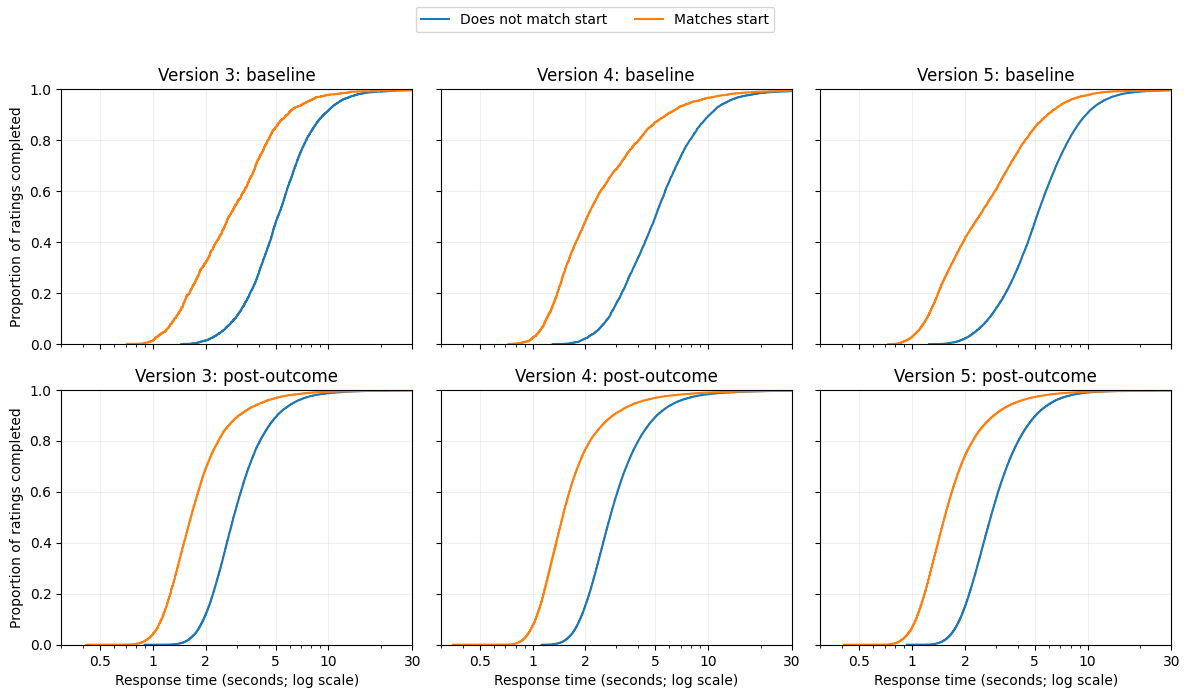

In [16]:
fig, axes = plt.subplots(
    2, 3, figsize=(12, 7), sharex=True, sharey=True
)

for row_index, timing in enumerate(["baseline", "post-outcome"]):
    for column_index, version in enumerate([3, 4, 5]):
        ax = axes[row_index, column_index]

        for matches_start, label, colour in [
            (False, "Does not match start", "tab:blue"),
            (True, "Matches start", "tab:orange"),
        ]:
            times = np.asarray(
                rt_by_match[(version, timing, matches_start)]
            )
            times = np.sort(
                times[np.isfinite(times) & (times > 0)]
            )
            cumulative = np.arange(1, len(times) + 1) / len(times)

            ax.step(
                times, cumulative, where="post",
                label=label, color=colour,
            )

        ax.set_xscale("log")
        ax.set_xlim(0.3, 30)
        ax.set_ylim(0, 1)
        ax.set_xticks([0.5, 1, 2, 5, 10, 30])
        ax.set_xticklabels(["0.5", "1", "2", "5", "10", "30"])
        ax.set_title(f"Version {version}: {timing}")
        ax.grid(alpha=0.2)

        if column_index == 0:
            ax.set_ylabel("Proportion of ratings completed")
        if row_index == 1:
            ax.set_xlabel("Response time (seconds; log scale)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

Matching ratings (orange) tend to have shorter response times, with substantial overlap between groups. The curves use all positive, finite RTs. No speed cutoff is applied.

This is not proof of disengagement: the act of changing the rating rquires slider movement, which in itself may take longer. Faster matching responses could reflect reduced interation, deliberate acceptance of the starting value, or both. 

### Recorded starting-value assignment

The dictionary says starts are random between 25–75 in versions 3–5. Look at the recorded values by rating position, then at successive starts. Position 0 is baseline.

Notebook 2 also found seven version-1 plays with non-50 starts. Keep their recorded labels.

In [21]:
starts_by_position = {}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in (3, 4, 5):
            continue

        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for position, row in enumerate(rating_rows):
            key = (version, position)
            starts_by_position.setdefault(key, []).append(play[row, 10]) # make an empty list if one doesn’t already exist then add the start value to it

In [20]:
start_position_rows = []

for (version, position), values in sorted(starts_by_position.items()):
    values = np.asarray(values)

    # check before removing tiny floating-point noise
    assert np.all(np.isfinite(values))
    assert np.all(np.isclose(
        values, np.rint(values), rtol=0, atol=1e-10
    ))
    starts = np.rint(values).astype(int)

    start_position_rows.append({
        "version": version,
        "rating_position": position,
        "ratings": len(starts),
        "distinct_starts": len(np.unique(starts)),
        "minimum": starts.min(),
        "maximum": starts.max(),
        "mean_start": starts.mean(),
        "percent_start_50": 100 * np.mean(starts == 50),
    })

start_position_summary = pd.DataFrame(start_position_rows)

start_position_summary.style.format({
    "mean_start": "{:.2f}",
    "percent_start_50": "{:.2f}",
}).hide(axis="index")

version,rating_position,ratings,distinct_starts,minimum,maximum,mean_start,percent_start_50
3,0,5456,50,25,74,49.85,1.78
3,1,5456,50,25,74,49.23,2.00
3,2,5456,50,25,74,49.28,1.94
3,3,5456,50,25,74,49.56,1.94
3,4,5456,50,25,74,49.55,2.22
3,5,5456,50,25,74,49.62,2.16
3,6,5456,50,25,74,49.29,1.92
3,7,5456,50,25,74,49.59,2.24
3,8,5456,50,25,74,49.64,2.25
3,9,5456,50,25,74,49.46,2.33


The ranges and summaries look similar across rating positions. No obvious shift at the matching peaks.

Heatmaps next: roughly uniform starts would give similar color throughout, approx. 2% per value.

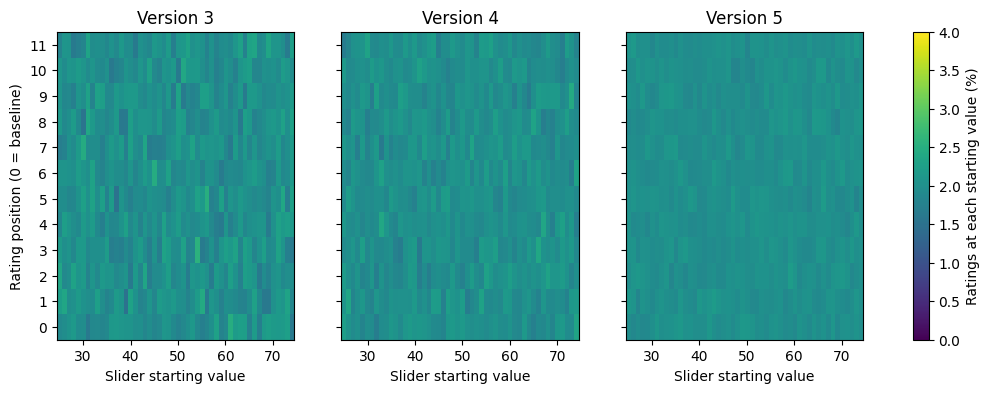

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
start_values = np.arange(25, 75)

for ax, version in zip(axes, [3, 4, 5]):
    percentages = []

    for position in range(12):
        starts = np.rint(
            starts_by_position[(version, position)]
        ).astype(int)

        percentages.append([
            100 * np.mean(starts == value)
            for value in start_values
        ])

    image = ax.imshow(
        percentages, aspect="auto", origin="lower",
        extent=[24.5, 74.5, -0.5, 11.5],
        cmap="viridis", vmin=0, vmax=4,
    )
    ax.set_title(f"Version {version}")
    ax.set_xlabel("Slider starting value")
    ax.set_yticks(range(12))

axes[0].set_ylabel("Rating position (0 = baseline)")
fig.colorbar(
    image, ax=axes.tolist(),
    label="Ratings at each starting value (%)",
)
plt.show()

The heatmaps look broadly even across positions. Version 5 is smoother, which makes sense with more plays. This checks the distributions, not whether successive draws are independent.

### Consecutive starting values within plays

Check whether successive slider starting values are linearly related.
Pairs remain within plays, i.e. no pair crosses a play boundary.

In [23]:
start_pairs = {version: [] for version in (3, 4, 5)}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in start_pairs:
            continue

        has_rating = ~np.isnan(play[:, 9])
        starts = play[has_rating, 10]

        # combine into pairs of consecutive ratings for each version, each tuple representing the start values of two consecutive ratings
        start_pairs[version].extend(
            zip(starts[:-1], starts[1:])
        )

In [24]:
serial_summary = []

for version, pairs in sorted(start_pairs.items()):
    pairs = np.asarray(pairs)
    previous = pairs[:, 0]
    following = pairs[:, 1]

    serial_summary.append({
        "version": version,
        "pairs": len(pairs),
        "correlation": np.corrcoef(previous, following)[0, 1],
        "percent_same_start": 100 * np.mean(
            np.isclose(previous, following, rtol=0, atol=1e-10)
        ),
    })

pd.DataFrame(serial_summary)

,version,pairs,correlation,percent_same_start
0,3,60016,-0.005232,2.027793
1,4,117524,0.001733,1.998741
2,5,423786,-0.003226,1.958536


Consecutive starts have correlations near zero and repeat about 2% of the time. That fits the documented random-start behaviour, but these summaries alone don’t verify the app’s assignment code.

## 3. Agreement and response patterns (full release)

Look at where matching occurs: across rating positions, starting values, plays and people. The RT comparison is above.

### Variation between rating positions

Matching percentages use all ratings. RT medians use positive, finite times, separately for matching and nonmatching responses.

In [17]:
position_groups = {}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in (3, 4, 5):
            continue

        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for position, row in enumerate(rating_rows):
            key = (version, position)

            if key not in position_groups:
                position_groups[key] = {"times": [], "matches": []}

            position_groups[key]["times"].append(play[row, 11])
            position_groups[key]["matches"].append(bool(np.isclose(
                play[row, 9], play[row, 10], rtol=0, atol=1e-10
            ))) # allows for floating point precision issues

position_summary = []

for (version, position), group in sorted(position_groups.items()):
    times = np.asarray(group["times"])
    matches = np.asarray(group["matches"])
    positive = np.isfinite(times) & (times > 0)

    position_summary.append({
        "version": version,
        "rating_position": position,
        "ratings": len(times),
        "percent_matching": 100 * matches.mean(),
        "median_RT_match": np.median(times[positive & matches]),
        "median_RT_nonmatch": np.median(times[positive & ~matches]),
    })

position_summary = pd.DataFrame(position_summary)

position_summary.style.format({
    "percent_matching": "{:.2f}",
    "median_RT_match": "{:.2f}",
    "median_RT_nonmatch": "{:.2f}",
}).hide(axis="index")

version,rating_position,ratings,percent_matching,median_RT_match,median_RT_nonmatch
3,0,5456,19.35,2.70,5.14
3,1,5456,22.76,2.33,3.87
3,2,5456,21.02,1.89,3.25
3,3,5456,22.09,1.74,3.08
3,4,5456,23.92,1.68,2.91
3,5,5456,22.98,1.63,2.85
3,6,5456,22.95,1.60,2.77
3,7,5456,23.85,1.57,2.71
3,8,5456,25.37,1.52,2.70
3,9,5456,24.62,1.55,2.67


Both RT medians fall sharply oer the early ratings, then decline more slowly. Matchin pecentages generally rise. These are pooled though, so people contributing to matching and nonmatching groups can change at each position. 

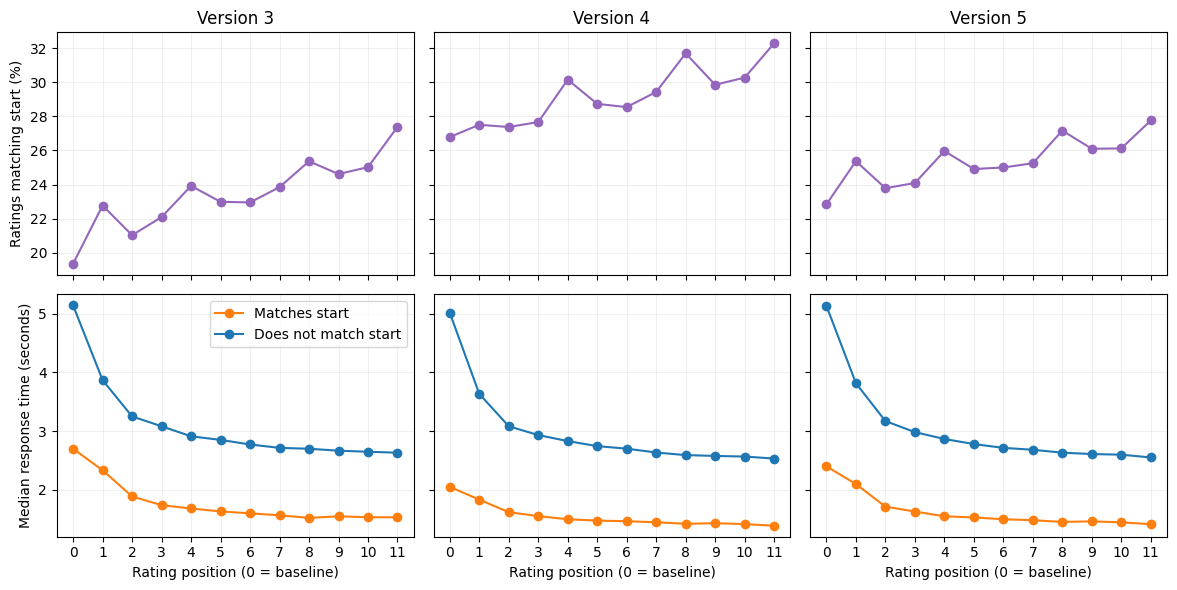

In [18]:
# Plot separately so percentages and RTs aren't mixed on one axis

fig, axes = plt.subplots(
    2, 3, figsize=(12, 6), sharex=True, sharey="row"
)

for column, version in enumerate([3, 4, 5]):
    data = position_summary[
        position_summary["version"] == version
    ].sort_values("rating_position")

    x = data["rating_position"]

    axes[0, column].plot(
        x, data["percent_matching"], marker="o", color="tab:purple"
    )
    axes[0, column].set_title(f"Version {version}")

    axes[1, column].plot(
        x, data["median_RT_match"],
        marker="o", color="tab:orange", label="Matches start",
    )
    axes[1, column].plot(
        x, data["median_RT_nonmatch"],
        marker="o", color="tab:blue", label="Does not match start",
    )

    for row in [0, 1]:
        axes[row, column].set_xticks(range(12))
        axes[row, column].grid(alpha=0.2)

    axes[1, column].set_xlabel("Rating position (0 = baseline)")

axes[0, 0].set_ylabel("Ratings matching start (%)")
axes[1, 0].set_ylabel("Median response time (seconds)")
axes[1, 0].legend()

fig.tight_layout()
plt.show()

Matching generally increases across rating positions, while median RT decreases in both response groups. Matching peaks at positions 4 and 8, which follow two-trial intervals; the final rating, position 11, also follows a two-trial interval and has the highest matching proportion in each version. These pooled patterns do not establish the causes of the changes, but it's noteworthy.

### Happiness across slider starting values

Summarise happiness and exact agreement at each recorded starting value,
separately by task version and baseline/post-outcome timing.

In [25]:
happiness_by_start = {}

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in (3, 4, 5):
            continue

        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for row in rating_rows:
            timing = "baseline" if row == 0 else "post-outcome"
            start = play[row, 10]

            # check before removing floating-point noise
            assert np.isclose(start, np.rint(start), rtol=0, atol=1e-10)
            start = int(np.rint(start))
            key = (version, timing, start)

            happiness_by_start.setdefault(key, []).append(play[row, 9])

In [27]:
happiness_start_rows = []

for (version, timing, start), values in sorted(happiness_by_start.items()):
    values = np.asarray(values)

    happiness_start_rows.append({
        "version": version,
        "timing": timing,
        "startValue": start,
        "ratings": len(values),
        "mean_happiness": values.mean(),
        "percent_matching": 100 * np.mean(
            np.isclose(values, start, rtol=0, atol=1e-10)
        ),
    })

happiness_start_summary = pd.DataFrame(happiness_start_rows)

print("Summary rows:", len(happiness_start_summary))
happiness_start_summary.head()

Summary rows: 300


,version,timing,startValue,ratings,mean_happiness,percent_matching
0,3,baseline,25,104,59.528846,6.730769
1,3,baseline,26,107,57.439252,13.084112
2,3,baseline,27,112,55.857143,8.928571
3,3,baseline,28,118,56.796610,12.711864
4,3,baseline,29,106,55.377358,14.150943


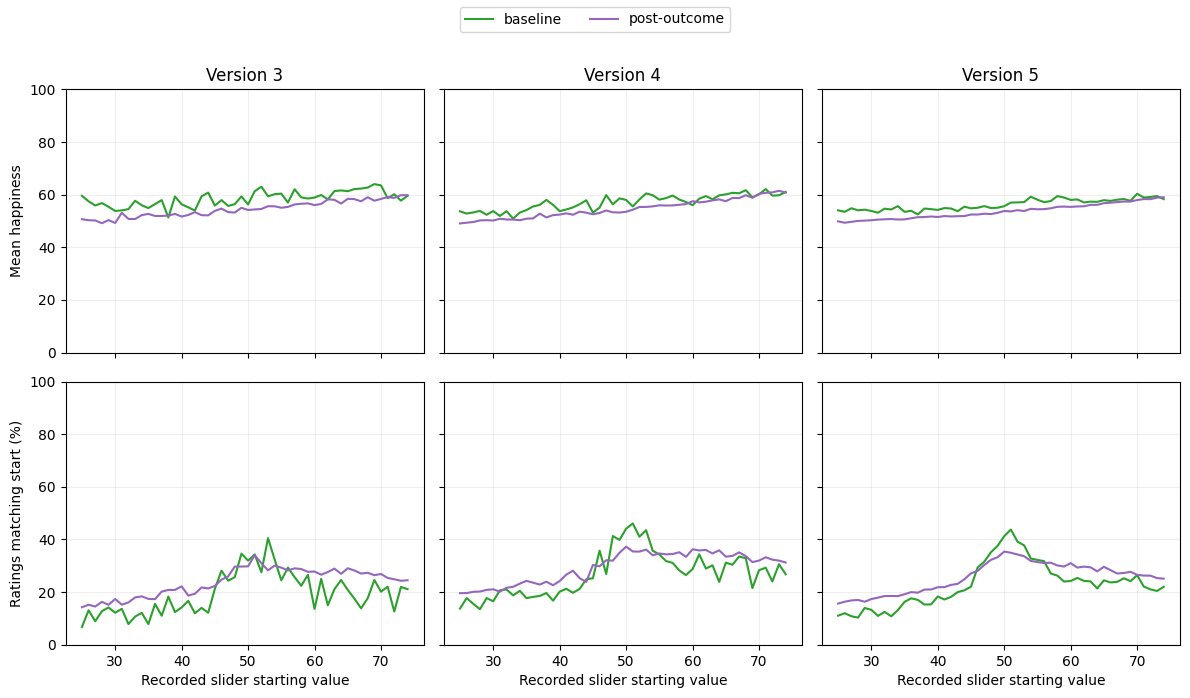

In [28]:
fig, axes = plt.subplots(
    2, 3, figsize=(12, 7), sharex=True, sharey="row"
)

for column, version in enumerate([3, 4, 5]):
    for timing, colour in [
        ("baseline", "tab:green"),
        ("post-outcome", "tab:purple"),
    ]:
        data = happiness_start_summary[
            (happiness_start_summary["version"] == version)
            & (happiness_start_summary["timing"] == timing)
        ].sort_values("startValue")

        axes[0, column].plot(
            data["startValue"], data["mean_happiness"],
            color=colour, label=timing,
        )
        axes[1, column].plot(
            data["startValue"], data["percent_matching"],
            color=colour, label=timing,
        )

    axes[0, column].set_title(f"Version {version}")
    axes[1, column].set_xlabel("Recorded slider starting value")

    for row in [0, 1]:
        axes[row, column].set_ylim(0, 100)
        axes[row, column].grid(alpha=0.2)

axes[0, 0].set_ylabel("Mean happiness")
axes[1, 0].set_ylabel("Ratings matching start (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=[0, 0, 1, 0.93])

plt.show()

Mean happiness rises with starting value in all three versions, at baseline and afterwards. Matching is especially common near 50. The mean curves don’t tell me how much comes from exact matching versus a pull on the other responses; the synthetic examples below help unpack that.

### Is matching concentrated in particular plays?

Count how many of the 12 ratings match the starting value in each play.
Keep versions 3–5 separate. 

In [36]:
play_matching_rows = []

for participant in participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in (3, 4, 5):
            continue

        has_rating = ~np.isnan(play[:, 9])
        happiness = play[has_rating, 9]
        starts = play[has_rating, 10]

        matches = np.isclose(
            happiness, starts, rtol=0, atol=1e-10
        )

        play_matching_rows.append({
            "id": participant["id"],
            "available_play": play_index + 1,
            "version": version,
            "rating_count": len(matches),
            "matching_ratings": int(matches.sum()),
        })

play_matching = pd.DataFrame(play_matching_rows)

matching_distribution = pd.crosstab(
    play_matching["matching_ratings"],
    play_matching["version"],
).reindex(index=range(13), columns=[3, 4, 5], fill_value=0)

matching_distribution

version,3,4,5
matching_ratings,,,
0,1107,1808,7176
1,1025,1690,6708
2,899,1625,6364
3,756,1425,5286
4,566,1022,3932
5,336,789,2754
6,235,577,1792
7,156,372,1198
8,93,282,783


In [37]:
play_match_overview = []

for version, group in play_matching.groupby("version"):
    counts = group["matching_ratings"]

    play_match_overview.append({
        "version": version,
        "plays": len(group),
        "percent_any_match": 100 * (counts > 0).mean(),
        "percent_all_12_match": 100 * (counts == 12).mean(),
        "share_of_matches_from_all_12_plays": (
            100 * counts[counts == 12].sum() / counts.sum()
        ),
    })

pd.DataFrame(play_match_overview)

,version,plays,percent_any_match,percent_all_12_match,share_of_matches_from_all_12_plays
0,3,5456,79.710411,2.272727,9.695074
1,4,10684,83.077499,4.333583,14.843312
2,5,38526,81.373618,2.411359,9.507808


There’s a clear all-match group, but it accounts for only a minority of matching ratings. Most matches occur in plays where participants also report values different from the start. Removing only the 12/12 plays would therefore leave most matching ratings in the data.

### Matching across a person’s plays

Summarise each person within each version. For repeat players, look at their lowest and highest match counts. More plays give more chances for a wide range, so don’t read that range as a stability score.

In [38]:
person_matching = (
    play_matching.groupby(["id", "version"]) #use play_matching to summarise each person within each version
    .agg(
        available_plays=("available_play", "size"),
        total_ratings=("rating_count", "sum"),
        total_matches=("matching_ratings", "sum"),
        fewest_matches_in_play=("matching_ratings", "min"),
        most_matches_in_play=("matching_ratings", "max"),
    )
    .reset_index()
)

person_matching["percent_matching"] = (
    100 * person_matching["total_matches"]
    / person_matching["total_ratings"]
)

person_matching["within_person_range"] = (
    person_matching["most_matches_in_play"]
    - person_matching["fewest_matches_in_play"]
)

# inspect people with repeat plays within the same version
repeat_person_matching = person_matching[
    person_matching["available_plays"] > 1
]

repeat_person_matching.head(10)

,id,version,available_plays,total_ratings,total_matches,fewest_matches_in_play,most_matches_in_play,percent_matching,within_person_range
5,128,4,2,24,4,1,3,16.666667,2
9,169,4,4,48,3,0,1,6.250000,1
11,262,5,2,24,8,1,7,33.333333,6
14,276,5,2,24,2,0,2,8.333333,2
15,280,3,4,48,11,1,6,22.916667,5
20,463,4,4,48,16,0,6,33.333333,6
23,552,4,2,24,10,5,5,41.666667,0
25,585,5,2,24,0,0,0,0.000000,0
27,667,4,3,36,4,1,2,11.111111,1
29,736,4,2,24,2,0,2,8.333333,2


The examples show both possibilities: same number of matches (ID 552) or variability (ID 262). But these are just the first ten rows and don't tell us how common either pattern is. A more useful comparison is the first two plays within the same version, giving each person one pair per version. This avoids frequent players contributing more pairs.

In [40]:
first_two_plays = (
    play_matching
    .sort_values(["id", "version", "available_play"])
    .groupby(["id", "version"])
    .head(2)
    .copy()
)

# add a play counter within each person–version pair (1 or 2)
first_two_plays["play_in_pair"] = (
    first_two_plays.groupby(["id", "version"]).cumcount() + 1
)

# turn the play_in_pair values into columns, so that each row represents a person–version pair with the matching ratings from their first and second plays in separate columns
play_pairs = first_two_plays.pivot(
    index=["id", "version"],
    columns="play_in_pair",
    values="matching_ratings",
).dropna(subset=[1, 2]) # only keep rows where both plays are present

play_pairs = play_pairs.rename(
    columns={1: "first_available", 2: "second_available"}
).reset_index()

print("Person–version pairs:", len(play_pairs))
play_pairs.columns.name = None # leftover pandas label
play_pairs.head()

Person–version pairs: 8866


,id,version,first_available,second_available
0,128,4,1.0,3.0
1,169,4,1.0,1.0
2,262,5,1.0,7.0
3,276,5,2.0,0.0
4,280,3,2.0,2.0


Scatterplot hides overlapping pair, instead we use a count heatmap separated by version.

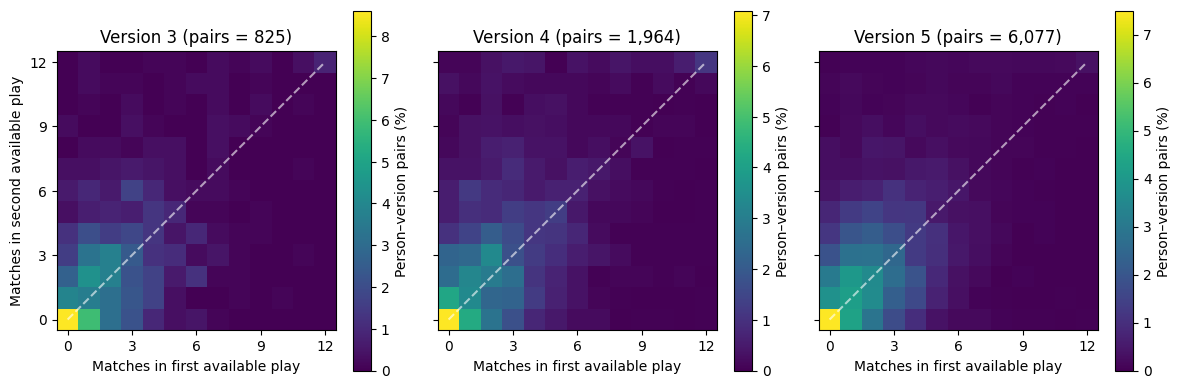

In [41]:
fig, axes = plt.subplots(
    1, 3, figsize=(12, 4), sharex=True, sharey=True
)

for ax, version in zip(axes, [3, 4, 5]):
    data = play_pairs[play_pairs["version"] == version]

    counts = pd.crosstab(
        data["second_available"], data["first_available"]
    ).reindex(
        index=range(13), columns=range(13), fill_value=0
    )

    # percentages within each version, so panel sizes are comparable
    percentages = 100 * counts / len(data)

    image = ax.imshow(
        percentages, origin="lower", aspect="equal",
        extent=[-0.5, 12.5, -0.5, 12.5],
        cmap="viridis",
    )
    ax.plot([0, 12], [0, 12], "--", color="white", alpha=0.6)
    ax.set_title(f"Version {version} (pairs = {len(data):,})")
    ax.set_xlabel("Matches in first available play")
    ax.set_xticks([0, 3, 6, 9, 12])

    fig.colorbar(image, ax=ax, label="Person–version pairs (%)")

axes[0].set_ylabel("Matches in second available play")
axes[0].set_yticks([0, 3, 6, 9, 12])

fig.tight_layout()
plt.show()

Becasue low-match counts are common in both plays, many pairs land near the lower-left diagonal and clustering along the diagonal line isn't enough to show stability.

In [42]:
pair_summary = []

for version, group in play_pairs.groupby("version"):
    first = group["first_available"]
    second = group["second_available"]

    pair_summary.append({
        "version": version,
        "pairs": len(group),
        "correlation": first.corr(second),
        "median_absolute_change": (second - first).abs().median(),
        "mean_first": first.mean(),
        "mean_second": second.mean(),
    })

pd.DataFrame(pair_summary)

,version,pairs,correlation,median_absolute_change,mean_first,mean_second
0,3,825,0.519555,1.0,2.480000,2.927273
1,4,1964,0.507343,2.0,2.834521,3.625255
2,5,6077,0.468691,2.0,2.536120,3.080796


Matching counts are moderately correlated across the first two available plays within each version (r = 0.47–0.52). The median absolute change is 1–2 ratings, and the second play has more matches on average. This doesn’t look like a simple split into permanently "matching" and "nonmatching" people.

## 4. Synthetic examples

These use made-up data, not a fitted GBE mechanism.

### Exact matching without partial anchoring

Make 25% of responses copy the start. The others come from a bounded distribution centred near 60, independently of the start.

In [29]:
rng = np.random.default_rng(42)
n = 100_000

synthetic_starts = rng.integers(25, 75, size=n)

# intended ratings are independent of slider starts,
# draw from normal distribution with mean 60 and standard deviation 20, then round to nearest integer and clip to range [0, 100]
intended_happiness = np.clip(
    np.rint(rng.normal(60, 20, size=n)), 0, 100
)

# for this example, 25% simply report the starting value
copies_start = rng.random(n) < 0.25
synthetic_happiness = np.where(
    copies_start, synthetic_starts, intended_happiness
)

synthetic = pd.DataFrame({
    "start": synthetic_starts,
    "happiness": synthetic_happiness,
    "matches": synthetic_happiness == synthetic_starts,
})

synthetic_summary = synthetic.groupby("start").agg(
    mean_happiness=("happiness", "mean"),
    percent_matching=("matches", "mean"),
)
synthetic_summary["percent_matching"] *= 100

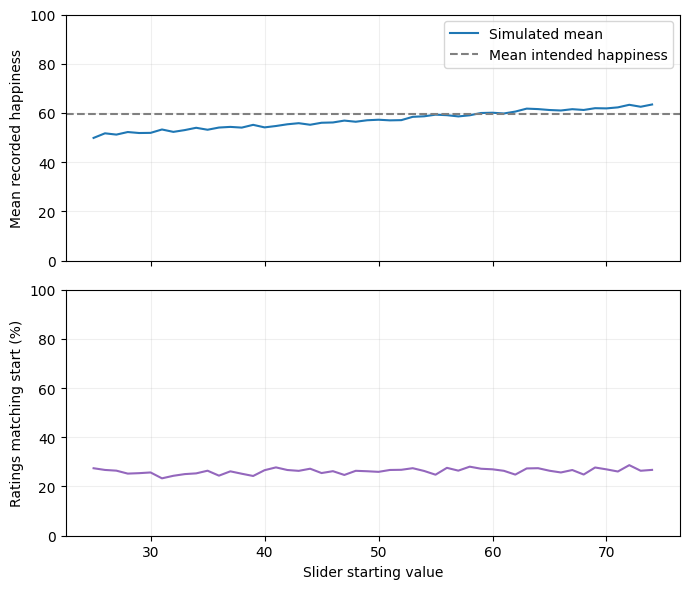

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)

axes[0].plot(
    synthetic_summary.index,
    synthetic_summary["mean_happiness"],
    label="Simulated mean",
)
axes[0].axhline(
    intended_happiness.mean(), color="grey", linestyle="--",
    label="Mean intended happiness",
)
axes[0].set_ylabel("Mean recorded happiness")
axes[0].legend()

axes[1].plot(
    synthetic_summary.index,
    synthetic_summary["percent_matching"],
    color="tab:purple",
)
axes[1].set_ylabel("Ratings matching start (%)")
axes[1].set_xlabel("Slider starting value")

for ax in axes:
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

Copying alone gives an upward mean curve, even though the other responses ignore the start. It doesn’t reproduce the strong variation in matching across starting values seen in GBE.

In [ ]:
# slopes in happiness points per one-point increase in slider start
intended_slope = np.polyfit(
    synthetic_starts, intended_happiness, deg=1
)[0]

# fit a straight line
recorded_slope = np.polyfit(
    synthetic_starts, synthetic_happiness, deg=1
)[0] # return the slope

print(f"Intended happiness slope: {intended_slope:.4f} (expected ≈ 0)")
print(f"Recorded happiness slope: {recorded_slope:.4f} (expected ≈ 0.25)")
print(f"Proportion assigned to copy: {copies_start.mean():.4f}")

Intended happiness slope: -0.0014 (expected ≈ 0)
Recorded happiness slope: 0.2524 (expected ≈ 0.25)
Proportion assigned to copy: 0.2512


The intended-rating slope is basically zero (−0.0014). The recorded slope is 0.2524, close to the 0.25 expected from copying; 25.12% were assigned to copy. So this pattern can appear without any partial anchoring.

In [32]:
# retain only ratings that differ from their starting value
nonmatching = ~np.isclose(
    synthetic_happiness, synthetic_starts, rtol=0, atol=1e-10
)

remaining_slope = np.polyfit(
    synthetic_starts[nonmatching],
    synthetic_happiness[nonmatching],
    deg=1,
)[0]

print(f"Ratings retained: {nonmatching.sum():,}")
print(f"Slope after removing exact matches: {remaining_slope:.4f}")

Ratings retained: 73,770
Slope after removing exact matches: -0.0095


Removing exact matches brings the slope close to zero, but slightly negative (−0.0095). Some genuine ratings were removed too, just because they happened to match the start. So dropping matches can help in this example, but we don’t yet know how well it would work with GBE.

### Add some partial anchoring

Same example, but non-copying responses now move 20% of the way from
intended happiness toward the slider start. This is just a chosen example,
not an estimate from GBE.

In [33]:
anchor_strength = 0.20

anchored_happiness = (
    (1 - anchor_strength) * intended_happiness
    + anchor_strength * synthetic_starts
) # i.e. 80% intended, 20% anchored to the starting value

# keep the same copying decisions as before
mixed_happiness = np.where(
    copies_start, synthetic_starts, anchored_happiness
)

# identify ratings that differ from their starting value
nonmatching_mixed = ~np.isclose(
    mixed_happiness, synthetic_starts, rtol=0, atol=1e-10
)

mixed_slope = np.polyfit(
    synthetic_starts, mixed_happiness, deg=1
)[0]

# slope after removing exact matches
mixed_remaining_slope = np.polyfit(
    synthetic_starts[nonmatching_mixed],
    mixed_happiness[nonmatching_mixed],
    deg=1,
)[0]

comparison = pd.DataFrame({
    "example": ["Copying only", "Copying + partial anchoring"],
    "all_ratings_slope": [recorded_slope, mixed_slope],
    "after_removing_matches": [remaining_slope, mixed_remaining_slope],
})

comparison.style.format({
    "all_ratings_slope": "{:.4f}",
    "after_removing_matches": "{:.4f}",
}).hide(axis="index")

example,all_ratings_slope,after_removing_matches
Copying only,0.2524,-0.0095
Copying + partial anchoring,0.4019,0.1924


Dropping exact matches mostly handles the copying-only example. But when the other responses are also pulled toward the start, that part remains: the slope falls from 0.4019 to 0.1924 (basically the 20% strength). So removing matches wouldn’t necessarily remove the whole starting-value effect.

## 5. Development data

The checks above used the full release. For the modelling next, use the 10,000 development participants and keep their plays together. The other 37,067 are reserved; exactly how they’ll be used for evaluation is still to be settled.

Load the assignments from [splits](../splits/README.md). Keep `participants` unchanged for the earlier cells, and make `development_participants` separately.

In [44]:
import hashlib

SPLIT_PATH = Path.cwd().parent / "splits" / "gbe_split_2026-10-07.csv"
EXPECTED_SPLIT_SHA256 = "861de3c444f506c76cbac3208840fd62d57a71b6aad63fceb83a802d8da139e9"

assert hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest() == EXPECTED_SPLIT_SHA256
split = pd.read_csv(SPLIT_PATH)

assert list(split.columns) == ["id", "set"]
assert pd.api.types.is_integer_dtype(split["id"])
assert split["id"].is_unique
assert set(split["set"]) == {"development", "holdout"}

# make sure no IDs are missing or invented relative to the loaded release
loaded_ids = [int(person["id"]) for person in participants]
assert len(loaded_ids) == len(set(loaded_ids))
assert set(split["id"]) == set(loaded_ids)

development_ids = set(split.loc[split["set"] == "development", "id"])
holdout_ids = set(split.loc[split["set"] == "holdout", "id"])
assert development_ids.isdisjoint(holdout_ids)
assert len(development_ids) == 10_000
assert len(holdout_ids) == 37_067

# leave participants unchanged; keep the released ordering in this subset
development_participants = [
    person for person in participants if int(person["id"]) in development_ids
]
assert len(development_participants) == 10_000

print("Split checksum and IDs verified.")
print("Development people:", len(development_participants))
print("Reserved hold-out IDs:", len(holdout_ids))

Split checksum and IDs verified.
Development people: 10000
Reserved hold-out IDs: 37067


In [45]:
# count coverage, without filtering or changing the split
coverage_rows = []
for version in range(1, 6):
    people_count = 0
    play_count = 0
    for person in development_participants:
        versions = np.atleast_1d(person["designVersion"])
        people_count += int(np.any(versions == version))
        play_count += int(np.sum(versions == version))
    coverage_rows.append({
        "version": version,
        "development_people": people_count,
        "development_plays": play_count,
    })

pd.DataFrame(coverage_rows)


,version,development_people,development_plays
0,1,3413,7323
1,2,100,358
2,3,760,1164
3,4,1148,2373
4,5,4860,8246


People can appear in more than one version row. These counts are before exclusions.

## 6. Start position and happiness within plays

### Prepare the development data
One row per post-outcome rating from development participants, versions 3–5. Keep all recorded ratings for now, including matches and ratings with flagged RTs.

In [46]:
development_rating_rows = []

for participant in development_participants:
    versions = np.atleast_1d(participant["designVersion"])

    for play_index, play in enumerate(get_plays(participant)):
        version = int(versions[play_index])
        if version not in (3, 4, 5):
            continue

        rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))

        for position, row in enumerate(rating_rows):
            if position == 0:
                continue  # baseline needs a separate comparison

            development_rating_rows.append({
                "id": int(participant["id"]),
                "available_play": play_index + 1,
                "version": version,
                "rating_position": position,
                "trial_number": int(play[row, 0]),
                "happiness": play[row, 9],
                "startValue": play[row, 10],
                "happinessRT": play[row, 11],
            })

development_ratings = pd.DataFrame(development_rating_rows)

print("People:", development_ratings["id"].nunique())
print("Plays:", development_ratings[
    ["id", "available_play"]
].drop_duplicates().shape[0])
print("Post-outcome ratings:", len(development_ratings))

development_ratings.head()

People: 6675
Plays: 11783
Post-outcome ratings: 129613


,id,available_play,version,rating_position,trial_number,happiness,startValue,happinessRT
0,128,2,4,1,3,50.0,33.0,11.251
1,128,2,4,2,6,52.0,32.0,3.366
2,128,2,4,3,9,29.0,37.0,2.886
3,128,2,4,4,11,31.0,48.0,7.898
4,128,2,4,5,14,39.0,29.0,4.886


### Centre starts within each play

Express each start relative to that play’s average. The check below should be effectively zero.

In [ ]:
play_keys = ["id", "available_play"]

# subtract the mean start value within each play from each rating's start value, so that the new column represents how far above or below the play's average start value each rating is
development_ratings["start_within_play"] = (
    development_ratings["startValue"]
    - development_ratings.groupby(play_keys)["startValue"].transform("mean")
)

# check the centering by finding the largest mean across all plays. should be approximately zero in every play, since the mean start value was subtracted from each rating's start value
largest_mean = (
    development_ratings.groupby(play_keys)["start_within_play"]
    .mean()
    .abs()
    .max()
)

print("Largest absolute play mean after centering:", largest_mean)

Largest absolute play mean after centering: 7.105427357601002e-15


### Prepare version 3

Compare ratings within plays, allowing for rating position. Remove the play averages from happiness and all predictor columns, including the indicators. This does the job of separate play intercepts without creating thousands of columns.

In [ ]:
import statsmodels.api as sm

version3 = development_ratings[
    development_ratings["version"] == 3
].copy()

play_keys = ["id", "available_play"]

# one indicator column for each position except the reference, position 1
position_terms = pd.get_dummies(
    version3["rating_position"],
    prefix="position",
    drop_first=True, #position 1 is the reference category
    dtype=float,
)

# build predictor matrix with the centered start value and the position indicator columns
X = pd.concat([
    version3[["start_within_play"]],
    position_terms,
], axis=1) # join the two dataframes together along the columns

# subtract each play's average from all model terms
groupers = [version3[key] for key in play_keys]
X_within = X - X.groupby(groupers).transform("mean") # centering the 0/1 indicator predictor columns because we're removing the play intercepts from the whoe model, resulting in 10/11 or -1/11
y_within = (
    version3["happiness"]
    - version3.groupby(play_keys)["happiness"].transform("mean") # center the outcomes
)

print("Ratings:", len(version3))
print("Plays:", version3[play_keys].drop_duplicates().shape[0])
print("People:", version3["id"].nunique())
print("Predictor columns:", X_within.columns.tolist())

Ratings: 12804
Plays: 1164
People: 760
Predictor columns: ['start_within_play', 'position_2', 'position_3', 'position_4', 'position_5', 'position_6', 'position_7', 'position_8', 'position_9', 'position_10', 'position_11']


### Fit version 3 and calculate uncertainty

Keep exact matches. Cluster uncertainty by person and count the removed play intercepts in the variance correction. The correction affects the SE and confidence interval, not the slope.

In [8]:
from scipy.stats import t

# apply ordinary least squares regression to the centered data, clustering standard errors by participant ID, since multiple ratings from the same participant can introduce correlation
fit_v3 = sm.OLS(y_within, X_within).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": version3["id"],
        "use_correction": False, # manual correction to account for small sample size
    },
)

# small-sample correction, counting the removed play intercepts
n_ratings = len(version3)
n_plays = version3[play_keys].drop_duplicates().shape[0]
n_people = version3["id"].nunique()
n_predictors = np.linalg.matrix_rank(X_within.to_numpy()) # number of predictor columns, matrix rank because some cols may be reduntant

# adjustment to clustered variance estimate for the limited sample size
correction = (
    n_people / (n_people - 1)
    * (n_ratings - 1) / (n_ratings - n_plays - n_predictors)
)

slope = fit_v3.params["start_within_play"]
# retrieve the estimated variance of the slope (table of coefficient variances and covariances)
slope_variance = fit_v3.cov_params().loc[
    "start_within_play", "start_within_play"
]
adjusted_variance = slope_variance * correction
#convert to standard error
se = np.sqrt(adjusted_variance)

# using 95% two-sided confidence interval, so the upper boundary is at cumprob 1-0.025 = 0.975, ppf returns the t-value with 97.5% of the distribution to its left, slightly above 1.96 with 759 df (n_people - 1)
#calculate confidence-interval margin
margin = t.ppf(0.975, df=n_people - 1) * se

print(f"Start-position slope: {slope:.4f}")
print(f"Participant-clustered SE: {se:.4f}")
print(f"95% CI: [{slope - margin:.4f}, {slope + margin:.4f}]")
print(f"Per 10-point higher start: {10 * slope:.2f} happiness points")

Start-position slope: 0.2102
Participant-clustered SE: 0.0186
95% CI: [0.1736, 0.2468]
Per 10-point higher start: 2.10 happiness points


Within plays, higher slider starts go with higher happiness ratings: about 2.1 happiness points per 10-point increase in start (95% CI: 1.74–2.47). This includes exact matches, so it doesn’t tell me how much comes from copying versus partial anchoring.

### Repeat for versions 4 and 5

Same model and uncertainty calculation for each version. Include version 3 again as a check against the worked example. Interval columns are for a one-point increase in start; the last column shows the association per 10 points.

In [9]:
# same model for each version, including version 3 as a cross-check
version_model_rows = []

for version in (3, 4, 5):
    data = development_ratings[development_ratings["version"] == version].copy()
    play_keys = ["id", "available_play"]

    # the transformation assumes the complete 11-position schedule checked earlier
    for _, play in data.groupby(play_keys):
        assert np.array_equal(np.sort(play["rating_position"]), np.arange(1, 12))

    positions = pd.get_dummies(
        data["rating_position"], prefix="position", drop_first=True, dtype=float
    )
    predictors = pd.concat([data[["start_within_play"]], positions], axis=1)
    groupers = [data[key] for key in play_keys]
    predictors_within = predictors - predictors.groupby(groupers).transform("mean")
    happiness_within = (
        data["happiness"]
        - data.groupby(play_keys)["happiness"].transform("mean")
    )

    fit = sm.OLS(happiness_within, predictors_within).fit(
        cov_type="cluster",
        cov_kwds={"groups": data["id"], "use_correction": False},
    )

    n_ratings = len(data)
    n_plays = data[play_keys].drop_duplicates().shape[0]
    n_people = data["id"].nunique()
    n_predictors = np.linalg.matrix_rank(predictors_within.to_numpy())
    correction = (
        n_people / (n_people - 1)
        * (n_ratings - 1) / (n_ratings - n_plays - n_predictors)
    )

    slope = fit.params["start_within_play"]
    slope_variance = fit.cov_params().loc["start_within_play", "start_within_play"]
    se = np.sqrt(slope_variance * correction)
    margin = t.ppf(0.975, df=n_people - 1) * se

    version_model_rows.append({
        "version": version,
        "people": n_people,
        "plays": n_plays,
        "ratings": n_ratings,
        "slope": slope,
        "clustered_SE": se,
        "CI_low": slope - margin,
        "CI_high": slope + margin,
        "per_10_point_start": 10 * slope,
    })

version_model_summary = pd.DataFrame(version_model_rows)

# should reproduce the separately worked-through version-3 estimate
np.testing.assert_allclose(
    version_model_summary.loc[version_model_summary["version"] == 3, "slope"].iloc[0],
    fit_v3.params["start_within_play"], rtol=0, atol=1e-10,
)

version_model_summary.style.format({
    "slope": "{:.4f}", "clustered_SE": "{:.4f}",
    "CI_low": "{:.4f}", "CI_high": "{:.4f}",
    "per_10_point_start": "{:.2f}",
}).hide(axis="index")

version,people,plays,ratings,slope,clustered_SE,CI_low,CI_high,per_10_point_start
3,760,1164,12804,0.2102,0.0186,0.1736,0.2468,2.10
4,1148,2373,26103,0.2683,0.0172,0.2347,0.3020,2.68
5,4860,8246,90706,0.1924,0.0071,0.1784,0.2063,1.92


## 7. Current reasoning

Higher starts go with higher ratings within plays in all three versions. These estimates include exact matches, so they don’t separate copying from partial anchoring.

The synthetic examples show why dropping matches may leave some starting-value influence. No RT cutoff or rating exclusions chosen.

Next: build the development interval table for the reward-history checks. Then reproduce the documented happiness model and test the provisional mood × RPE model on synthetic data.